# Use Case 3: Statistical Insights and Patterns

In this notebook I dig a bit deeper into the data:
1. how crime varies by hour of the day
2. statistics per community area with NumPy, plus outlier detection (box plot and IQR)
3. correlations between the numeric columns

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

import crime_utils as cu

cu.set_style()
df = pd.read_pickle(cu.CLEAN_CRIME_FILE)
community = pd.read_pickle(cu.OUTPUT_DIR / "community_lookup.pkl")
print(f"{len(df):,} crimes loaded")

498 crimes loaded


## 1. Crime by hour of day
`df['date'].dt.hour` gives the hour, `groupby('hour').size()` counts crimes in each hour, and `reindex(range(24))` makes sure every hour is listed even if it has zero crimes.

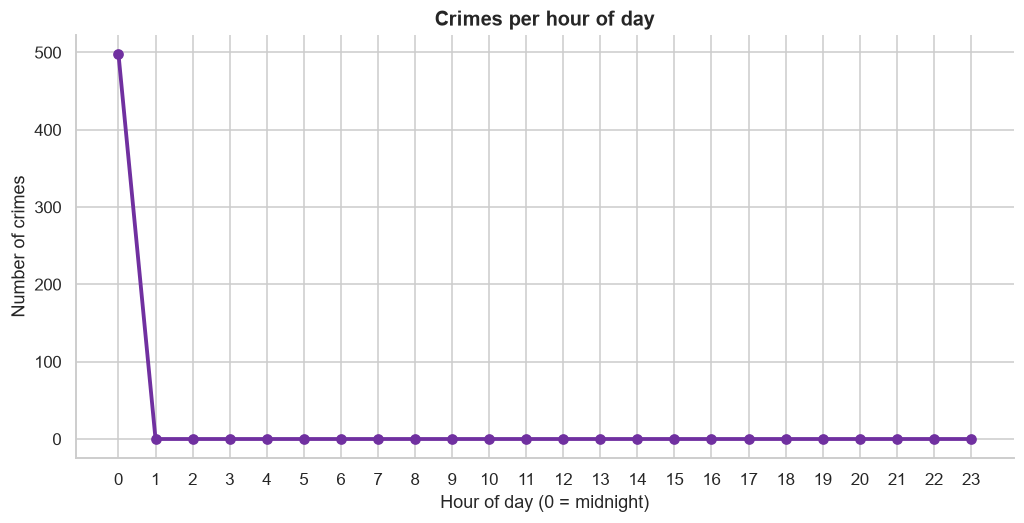

Every timestamp is 00:00 because the supplied file has dates only (e.g. 5/3/2016), so all 498 crimes land on hour 0. The brief's sample row has a time (5/3/2016 23:40), so this is a limitation of the supplied file.


In [2]:
df["hour"] = df["date"].dt.hour
crimes_by_hour = df.groupby("hour").size().reindex(range(24), fill_value=0)

fig, ax = plt.subplots()
ax.plot(crimes_by_hour.index, crimes_by_hour.values, marker="o", linewidth=2.5, color="#7030a0")
ax.set(title="Crimes per hour of day", xlabel="Hour of day (0 = midnight)", ylabel="Number of crimes")
ax.set_xticks(range(24))
cu.save_fig(fig, "uc3_01_crimes_per_hour")
plt.show()

if (df["date"].dt.time == pd.Timestamp(0).time()).all():
    print(f"Every timestamp is 00:00 because the supplied file has dates only (e.g. 5/3/2016), so all "
          f"{len(df):,} crimes land on hour 0. The brief's sample row has a time (5/3/2016 23:40), so this "
          "is a limitation of the supplied file.")

## 2. Community areas with NumPy

First I get one number for each community area: its crime count (areas with no crimes count as 0). Then `np.mean` over the 77 counts gives the average number of crimes per community area.

In [3]:
counts = (df["community_code"].dropna().astype(int).value_counts()
            .reindex(community["community_code"].astype(int), fill_value=0))
names = community.set_index(community["community_code"].astype(int))["community_name"].str.title()

arr = counts.to_numpy()                       # plain NumPy array of 77 counts
print(f"Mean crimes per community area: {np.mean(arr):.2f}")

Mean crimes per community area: 6.47


### Outliers: box plot and IQR

The interquartile range (IQR) is Q3 minus Q1, i.e. the spread of the middle half of the data.
A value counts as an outlier if it falls outside these limits:

* lower limit = Q1 - 1.5 x IQR
* upper limit = Q3 + 1.5 x IQR

A box plot uses the same rule to draw its whiskers and points, so the box plot shows the outliers visually and the IQR calculation gives the actual list.

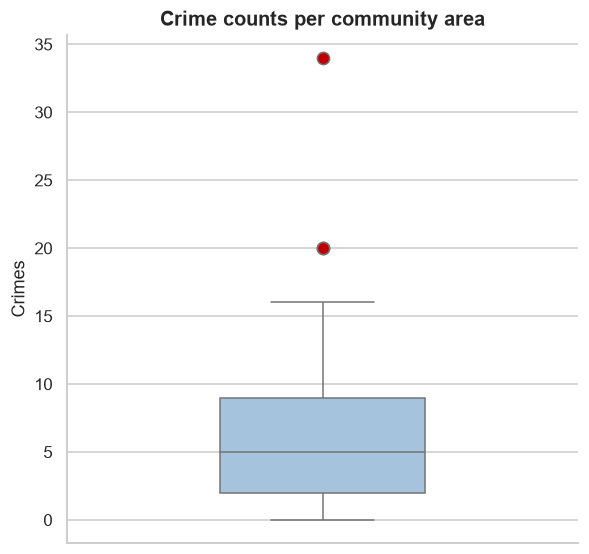

Q1 = 2.0  Q3 = 9.0  IQR = 7.0
Fences: lower = -8.5, upper = 19.5


In [4]:
q1, q3 = np.percentile(arr, [25, 75])
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr

fig, ax = plt.subplots(figsize=(6, 6))
sns.boxplot(y=arr, ax=ax, color="#9dc3e6", width=.4,
            flierprops=dict(marker="o", markerfacecolor="#c00000", markersize=8))
ax.set(title="Crime counts per community area", ylabel="Crimes")
cu.save_fig(fig, "uc3_03_community_boxplot")
plt.show()

print(f"Q1 = {q1:,.1f}  Q3 = {q3:,.1f}  IQR = {iqr:,.1f}")
print(f"Fences: lower = {lower:,.1f}, upper = {upper:,.1f}")

In [5]:
is_outlier = (arr < lower) | (arr > upper)
outliers = (pd.DataFrame({"community_name": names.reindex(counts.index), "crimes": arr}, index=counts.index)
              [is_outlier].sort_values("crimes", ascending=False))
print(f"{is_outlier.sum()} extreme outlier community area(s):")
display(outliers)
if lower < 0:
    print("Note: the lower fence is negative, so only unusually high-crime areas can be flagged.")

3 extreme outlier community area(s):


,community_name,crimes
community_code,,
25,Austin,34
8,Near North Side,20
23,Humboldt Park,20


Note: the lower fence is negative, so only unusually high-crime areas can be flagged.


## 3. Correlation between columns

`.corr()` calculates the Pearson correlation (from -1 to +1) for every pair of numeric columns. I convert `arrest` and `domestic` to 0/1 so they can be included, and day of week to a number (Monday = 0). Rough guide: around 0 means no linear relationship, ±0.3 weak, ±0.5 moderate, ±0.7 or more strong. Columns like `district_code` and `ward_no` are ID labels, so a correlation between them only reflects how the numbers were assigned across the city.

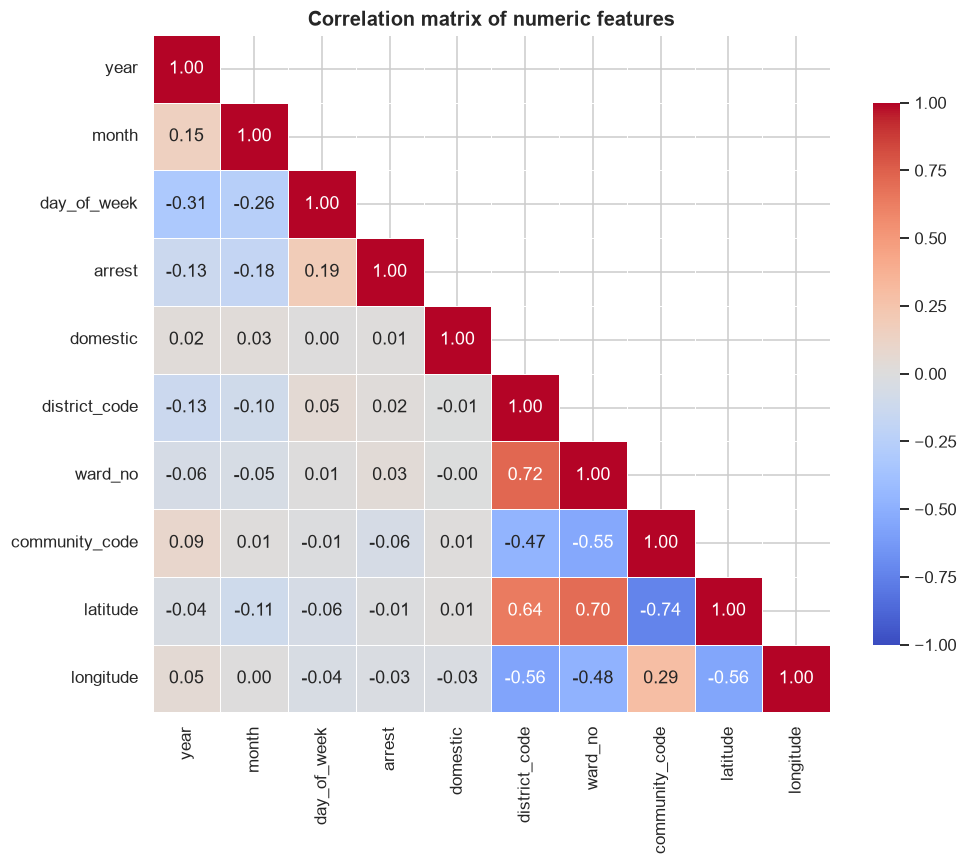

In [6]:
# hour is left out: it is 0 for every row (no times in the file), so it has no variance
num = pd.DataFrame({
    "year": df["year"], "month": df["month"],
    "day_of_week": df["date"].dt.day_of_week,
    "arrest": df["arrest"].astype(int), "domestic": df["domestic"].astype(int),
    "district_code": df["district_code"], "ward_no": df["ward_no"],
    "community_code": df["community_code"],
    "latitude": df["latitude"], "longitude": df["longitude"],
})
corr = num.corr()

fig, ax = plt.subplots(figsize=(10, 8))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)       # hide the duplicate upper triangle
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            center=0, linewidths=.5, square=True, ax=ax, cbar_kws={"shrink": .8})
ax.set_title("Correlation matrix of numeric features")
cu.save_fig(fig, "uc3_04_correlation_heatmap")
plt.show()

In [7]:
pairs = corr.where(~np.tril(np.ones_like(corr, dtype=bool))).stack()
a, b = pairs.abs().idxmax()
print(f"The strongest pairs are location codes (e.g. {a} vs {b}, r = {pairs[(a, b)]:.2f}), which is geography.")
print(f"Arrest vs year: r = {corr.loc['arrest', 'year']:.2f}, a weak relationship.")

The strongest pairs are location codes (e.g. community_code vs latitude, r = -0.74), which is geography.
Arrest vs year: r = -0.13, a weak relationship.
